# TRANSFER LEARNING

In [20]:
from __future__ import print_function, division
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

### Загрузка данных

Для загрузки данных используются пакеты torchvision и torch.utils.data.

Ссылка на набор данных - https://download.pytorch.org/tutorial/hymenoptera_data.zip

In [21]:
# Увеличение количества данных и их нормализация
# Нормализация для проверки
data_transforms = {
     'train': transforms.Compose([
         transforms.RandomResizedCrop(224),
         transforms.RandomHorizontalFlip(),
         transforms.ToTensor(),
         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
     ]),
     'val': transforms.Compose([
        transforms.Resize(256),
         transforms.CenterCrop(224),
         transforms.ToTensor(),
         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
     ]),
}

data_dir = 'hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                              shuffle=True, num_workers=4)
               for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

### Визуализация нескольких образцов

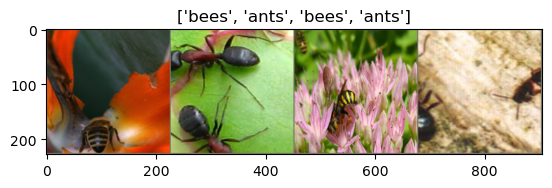

In [22]:
def imshow(inp, title=None):
    """Imshow для тензора."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

# Получение батча обучающего набора
inputs, classes = next(iter(dataloaders['train']))

# Делаем сетку из батча
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

### Обучение модели

Напишем общую функцию для обучения модели. Здесь можно настроить:
1. Планирование скорости обучения
2. Сохранение лучшей модели

Параметр scheduler - это объект планировщика LR из torch.optim.lr_scheduler.

In [23]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
        
    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)
        
        # Для каждой эпохи прописываем этап обучения и волидации
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train() # Уставновка модели в режим обучения
            else:
                model.eval() # Set ставновка модели в режим оценки
             
            running_loss = 0.0
            running_corrects = 0
                
            # Перебор данных
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # Обнуление градиентов параметров
                optimizer.zero_grad()

                # Отслеживание истории батча при обучении
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    
                    # Оптимизация на этапе обучения
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                
                # Статистикаs
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()
                
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(
                phase, epoch_loss, epoch_acc))
            
            # Копирование модели
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
    time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))
    # Загрузка лучших весов модели
    model.load_state_dict(best_model_wts)
    return model

### Визуализация прогнозов модели

Общая функция для отображения прогнозов для нескольких изображений.

In [24]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title('predicted: {}'.format(class_names[preds[j]]))
                imshow(inputs.cpu().data[j])
                
                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

### Тонкая настройка сверточной сети

Загрузка предварительно обученной модели и сброс крайнего полно-связанного слоя.

In [25]:
model_ft = models.resnet18(pretrained=True)
num_ftrs = model_ft.fc.in_features
# Размер каждой выходной выборки установлен равным 2
# Альтернативно его можно обобщить до nn.Linear(num_ftrs, len(class_names))

model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Все параметры оптимизируются
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Уменьшение LR каддые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

### Тренировка и оценка

In [26]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 0.7081 Acc: 0.6434
val Loss: 0.2609 Acc: 0.9085

Epoch 1/24
----------
train Loss: 0.5367 Acc: 0.7664
val Loss: 0.5054 Acc: 0.8105

Epoch 2/24
----------
train Loss: 0.4663 Acc: 0.7951
val Loss: 0.4782 Acc: 0.8170

Epoch 3/24
----------
train Loss: 0.4349 Acc: 0.8484
val Loss: 0.2055 Acc: 0.9281

Epoch 4/24
----------
train Loss: 0.6295 Acc: 0.7787
val Loss: 0.2342 Acc: 0.9346

Epoch 5/24
----------
train Loss: 0.4909 Acc: 0.7664
val Loss: 0.2621 Acc: 0.8758

Epoch 6/24
----------
train Loss: 0.3680 Acc: 0.8525
val Loss: 0.2937 Acc: 0.9085

Epoch 7/24
----------
train Loss: 0.3539 Acc: 0.8525
val Loss: 0.2168 Acc: 0.9085

Epoch 8/24
----------
train Loss: 0.2750 Acc: 0.8852
val Loss: 0.1849 Acc: 0.9346

Epoch 9/24
----------
train Loss: 0.2339 Acc: 0.9016
val Loss: 0.2202 Acc: 0.9346

Epoch 10/24
----------
train Loss: 0.2308 Acc: 0.9098
val Loss: 0.1579 Acc: 0.9346

Epoch 11/24
----------
train Loss: 0.3215 Acc: 0.8402
val Loss: 0.1749 Acc: 0.9281

Ep

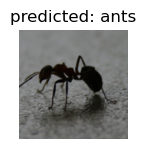

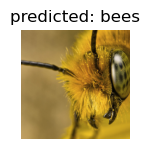

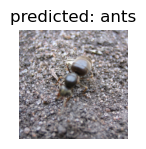

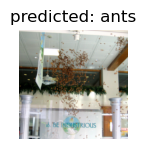

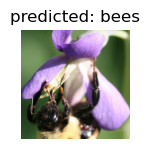

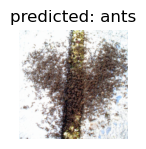

In [27]:
visualize_model(model_ft)

### ConvNet как средство извлечения фиксированных функций

Далее необходимо заморозить всю сеть, кроме последнего слоя. Необходимо установить замораживание параметров,
чтобы градиенты не вычислялись в .requires_grad = Falsebackward().

Подробнее об этом можно прочитать в документации здесь - https://pytorch.org/docs/master/notes/autograd.html

In [28]:
model_conv = torchvision.models.resnet18(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False

# Параметры вновь созданных модулей по умолчанию имеют require_grad=True.
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Оптимизируются только параметры последнего слоя, в отличие от предыдущего кода выше
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Уменьшение LR каддые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

### Тренировка и оценка

Здесь вы можете увидеть, что время сократилось. Это происходит потому, что градиенты больше не нужно
вычислять.


In [29]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.5993 Acc: 0.6762
val Loss: 0.2728 Acc: 0.8693

Epoch 1/24
----------
train Loss: 0.5695 Acc: 0.7664
val Loss: 0.7808 Acc: 0.7190

Epoch 2/24
----------
train Loss: 0.6055 Acc: 0.7336
val Loss: 0.1923 Acc: 0.9346

Epoch 3/24
----------
train Loss: 0.5382 Acc: 0.7787
val Loss: 0.3381 Acc: 0.8627

Epoch 4/24
----------
train Loss: 0.3989 Acc: 0.8361
val Loss: 0.2908 Acc: 0.8954

Epoch 5/24
----------
train Loss: 0.5957 Acc: 0.7910
val Loss: 0.2213 Acc: 0.9412

Epoch 6/24
----------
train Loss: 0.6373 Acc: 0.7336
val Loss: 0.2115 Acc: 0.9477

Epoch 7/24
----------
train Loss: 0.3852 Acc: 0.8525
val Loss: 0.2259 Acc: 0.9281

Epoch 8/24
----------
train Loss: 0.3688 Acc: 0.8566
val Loss: 0.2132 Acc: 0.9346

Epoch 9/24
----------
train Loss: 0.3145 Acc: 0.8648
val Loss: 0.2364 Acc: 0.9281

Epoch 10/24
----------
train Loss: 0.3107 Acc: 0.8525
val Loss: 0.2174 Acc: 0.9412

Epoch 11/24
----------
train Loss: 0.3172 Acc: 0.8689
val Loss: 0.2815 Acc: 0.9020

Ep

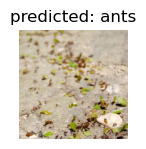

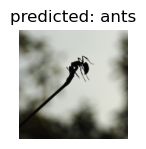

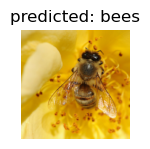

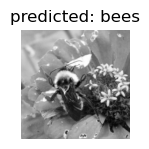

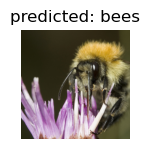

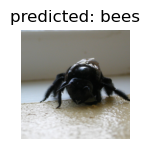

In [30]:
visualize_model(model_conv)
plt.ioff()
plt.show()